Module 6 - Forecasting Public Transportation Demand - Samuel Scott

## Part 1: Business Situation
### The Setting
Forecasting transportation demand matters for staffing, planning, and inventory control. The public
transportation system in Santiago de Chile went through a major effort of reconstruction, and in that
context a business intelligence competition was held in October 2006 focused on forecasting demand for
public transportation. This case is based on that competition, with some modifications.
A public transportation company is expecting an increase in demand for its services and is planning to
acquire new buses and extend its terminals. These investments require a reliable forecast of future
demand. The company's data warehouse holds, for each 15-minute interval between 6:30 and 22:00, the
number of passengers arriving at the terminal. As a forecasting consultant, you have been asked to
create a method that generates forecasts of the number of passengers arriving at the terminal

### The Data
Part of the historic information is available in Bicup2006.csv. The dataset holds known demand for a
three-week period (March 1 to March 21, 2005), separated into 15-minute intervals from 6:30 to 22:00 (63
intervals per day). It also contains the dates and times for a future three-day period with DEMAND left
blank (NaN), for which forecasts must be generated. Each row is one 15-minute interval and holds three
fields.

In [1]:
#!pip install pmdarima
#%pip show mlba

In [2]:
from datetime import date
import matplotlib.pyplot as plt
import mlba
import pandas as pd
import numpy as np
from sktime.forecasting.naive import NaiveForecaster
from sktime.forecasting.trend import PolynomialTrendForecaster
from sktime.split import temporal_train_test_split
from sktime.utils.plotting import plot_series
from sktime.forecasting.ardl import ARDL
from sktime.forecasting.arima import ARIMA
from sktime.forecasting.base import ForecastingHorizon
from sktime.forecasting.trend import PolynomialTrendForecaster, TrendForecaster
from sktime.pipeline import make_pipeline
from sktime.transformations.series.boxcox import LogTransformer
from sktime.utils.plotting import plot_series
from statsmodels.graphics.tsaplots import plot_acf
import warnings
warnings.filterwarnings('ignore')

### Question 1 - Exploratory Analysis

Use exploratory analysis to understand the series before you model it. Work through the following,
showing the plots and summaries that support each conclusion.

In [3]:
df = pd.read_csv('C:/Users/samsc/Desktop/ADS-505/bicup2006.csv')
df.head()

,DATE,TIME,DEMAND
0,1-Mar-05,6:30,1.0
1,1-Mar-05,6:45,2.0
2,1-Mar-05,7:00,4.0
3,1-Mar-05,7:15,0.0
4,1-Mar-05,7:30,10.0


In [4]:
df.shape

(1512, 3)

In [5]:
df.isna().sum()

DATE        0
TIME        0
DEMAND    189
dtype: int64

In [6]:
df.duplicated().sum() #no duplicates

np.int64(0)

In [7]:
#Checks for when passengers arrival 
df['DEMAND'].describe()

count    1323.000000
mean       25.872260
std        23.522793
min         0.000000
25%         4.000000
50%        23.000000
75%        40.000000
max       136.000000
Name: DEMAND, dtype: float64

### Approach to dealing with missing data:

### How many passengers on average throughout the day take the public transportation?

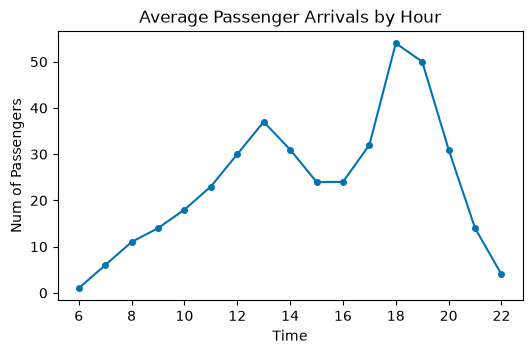

In [8]:
df['DATETIME'] = pd.to_datetime(df['DATE'] + ' ' + df['TIME'], format='%d-%b-%y %H:%M') 
public_trans_ts = pd.Series(df.DEMAND.values, index=df.DATETIME, name='Passengers')

#be able to graph the hours of the day
df['HOUR'] = df['DATETIME'].dt.hour
hourly_demand = df.groupby('HOUR')['DEMAND'].mean().astype('int') #make hourly_demand integer because demand is 
#number of people, which are not decimal values
#print(hourly_demand)

public_trans_ts = pd.Series(hourly_demand.values, index=hourly_demand.index, name='Passenger_Hours')

fig, ax = plt.subplots(figsize=[6, 3.5])
plot_series(public_trans_ts, ax=ax,
            x_label='Time', y_label='Num of Passengers')
plt.title("Average Passenger Arrivals by Hour")
plt.show()

### What days do passengers get on the public transportation (PT) the most? The least? 

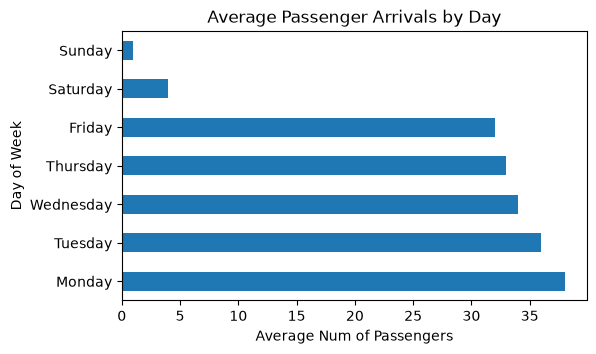

In [9]:
df['DAY_OF_WEEK'] = df['DATETIME'].dt.day_name()

daily_demand = df.groupby('DAY_OF_WEEK')['DEMAND'].mean().astype('int')
#print(daily_demand)

#reorder days of week since they are sorted by lexiographically order of day name
#used AI to help me sort the days in order
day_sort = ['Monday', 'Tuesday', 'Wednesday',
            'Thursday', 'Friday', 'Saturday', 'Sunday']
daily_demand = daily_demand.reindex(day_sort)

fig, ax = plt.subplots(figsize=[6, 3.5])
daily_demand.plot(kind='barh', ax=ax)
plt.title("Average Passenger Arrivals by Day")
plt.ylabel('Day of Week')
plt.xlabel('Average Num of Passengers')
plt.show()

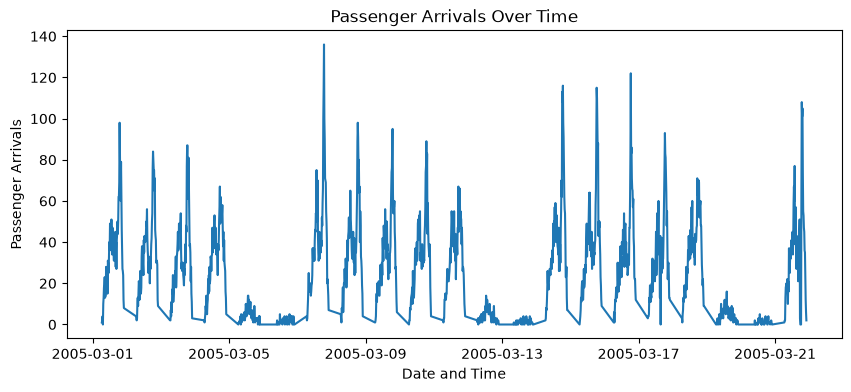

In [10]:
#Overall time series
fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(df['DATETIME'], df['DEMAND'])

plt.xlabel('Date and Time')
plt.ylabel('Passenger Arrivals')
plt.title('Passenger Arrivals Over Time')
plt.show()

#### 1.1 Identify the Time-Series Components
Is there a trend? Is there seasonality, and if so, how many seasonal cycles are present? Are there other
visible patterns? Are the patterns global (stable across the whole series) or local (changing over time)?

There are some trends that have been identified. First, the two visuals show that passengers travel or use PT for commuting to work mainly. This conclusion can be determined because the average daily passengers significantly decrease during the weekend days, and for the hours's time series passengers averages are highest between the hours of 10am-8pm. There are ever present season cycles but the peak in passenger values vary mainly on what day and especially what time of day it is. Due to that there are season, on the time series it is clear when there are two smaller amplitudes those represent Saturday and Sunday. These patterns I would say are global as I would imagine the time series throughout the whole year would look somewhat similar as these days are in the month of March, with the exception of the holiday season (Late November-Early January).

#### 1.2 Consider the Data Frequency
Consider the frequency of the data from both a practical and a technical point of view. What are some
options for how the frequency could be treated, and what are the trade-offs?

Frequency can be determined by what measurement you use for the time series as there are several approaches. The first approach is to not change the time-frequency and leave it up to 15 minute intervals. This would get the most accurate representation of your data but since they are so many data points it would be difficult to visual represent it and it would be the most computationally expensive data to build a model on, given you would use the same model for each approach. The second approach is to use hourly intervals and aggregate passenger amounts based on how many passengers on average are tracked. This would give us a better understanding of trends (like that it tracks people commuting on a work day vs it is late at night people are asleep). This would be easier to graph but not by much, since there would still be many intervals to track. Another approach is to use days as your unit of measure for the time series. I believe this approach would be best because it would be easiest to see trends and it would still retain most of the information the time series would need to estimate future predictive values. 

#### 1.3 Compare Weekdays and Weekends
Compare weekdays and weekends. How does the demand pattern differ between them, and how might
those differences be captured by different modeling methods?

Many more people are using PT when it is a week day. When it is a weekend far less PT is used. Depending on the modeling approach and what your data is those differences can be captured. Using a naive forecaster which captures the most recent value of the time series might have the model learn smaller series or learn a portion of a series really well but it might struggle to predict longer series. We can have this naive forecaster be used on days of the week or hourly and that can change the behavior of the model to capture differences. ARIMA models uses the correlation of the predictors to create predictions for the time series when you use exogenous variables. This approach would do a good job at plotting simple features but if complex relationships between predictors arises then it would be difficult to capture the differences. 

#### 1.4 Handle Missing and Unusual Values
Examine the series for missing or unusual values. Where do they occur, what might explain them, and
what are the options for handling them? State the approach you will use and why.

Since there are 3 days worth of missing data (the last three days) that is to be used for modeling so the approach here is to do nothing with it and let our model predict passenger count. 
Operating hours are from 6:30 to 22:00. This is shown as the hours between 22:00 and 6:30 do not have any data recorded leading us to believe that is when the PT is closed.

#### 1.5 Choose Candidate Methods
Based on the patterns you found, which models or methods should be considered for forecasting this
series?

-I like the models of Naive Forecaster as a baseline model.
-Seasonal Naive would track passenger arrivals based on daily/weekly patterns.
-Trend forecaster for studying linear, exponential and polynomial relationships. 
-ARIMA for studying seasonal patterns in the data/ 

### Question 2 - Build a Forecast Model
Based on your exploratory findings, build a model that forecasts demand while accounting for the
seasonal structure you identified. The aim is not simply the lowest error on the three future days (the
original competition's criterion) but a model that generates reasonably good forecasts at any time of any
day of the week.

#### 2.1 Partition the Data
Partition the three weeks of historic data into a training period (the first two weeks, March 1 to 14) and a
test period (the last week, March 15 to 21). Fit your models only to the training data and evaluate them on
the test period. The future three days (March 22 to 24) appear in the dataset with DEMAND = NaN and
are the forecast horizon.

In [11]:
df['DATETIME'] = pd.to_datetime(df['DATETIME'])
df = df.sort_values('DATETIME')
ts = df.set_index('DATETIME')['DEMAND']
ts = ts.asfreq('15min')
first_two_weeks = ts.loc['2005-03-01':'2005-03-14'] #training
third_week = ts.loc['2005-03-15':'2005-03-21'] #holdout
future_forecast = ts.loc['2005-03-22':'2005-03-24'] #test/model performance

#impute closed times with 0 passengers
first_two_weeks = first_two_weeks.fillna(0)
third_week = third_week.fillna(0)

#add these imputations back into our time series
ts_no_forecast = pd.concat([first_two_weeks, third_week])
ts = ts_no_forecast
ts = pd.concat([ts, future_forecast])

#### 2.2 Fit a Seasonal Model
Fit a forecasting model that captures both the daily (time-of-day) and weekly (day-of-week) seasonality.
One effective approach is a linear regression on a trend term plus categorical day-of-week and time-of-
day terms and their interaction; you may use this or another method you can justify. State the model
specification clearly enough that another analyst could reproduce it.

In [12]:
X = pd.DataFrame(index=ts.index) #create a dataframe with all timestamps

X['day_of_week'] = ts.index.dayofweek #retrieve day of week
X['time_of_day'] = ts.index.strftime('%H:%M') #retrieve time of day

#Convert categories into dummy variables
X = pd.get_dummies(X, columns=['day_of_week', 'time_of_day'], drop_first=True,dtype=int)

#Split predictors into training and holdout periods
first_two_weeks_X = X.loc[first_two_weeks.index]
third_week_X = X.loc[third_week.index]

In [13]:
forecaster_ARDL = ARDL(lags=0, order=0, trend='n', seasonal=False)
forecaster_ARDL.fit(first_two_weeks, X=first_two_weeks_X)
forecaster_ARDL.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                                                                                                                                                                ARDL Model Results                                                                                                                                                                                
==================================================================================================================================================================================================================================================================================================================================================================================
Dep. Variable:                                                                                                                                                                                                                                                                                                                     DEMAND   No. Observations:                 1318
Model:             ARDL(0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0)   Log Likelihood               -5071.881
Method:                                                                                                                                                                                                                                                                                                                   Conditional MLE   S.D. of innovations             11.350
Date:                                                                                                                                                                                                                                                                                                                    Tue, 13 Oct 2026   AIC                          10347.762
Time:                                                                                                                                                                                                                                                                                                                            18:36:33   BIC                          10876.517
Sample:                                                                                                                                                                                                                                                                                                                        03-01-2005   HQIC                         10546.017
                                                                                                                                                                                                                                                                                                                             - 03-14-2005                                         
========================================================================================
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
day_of_week_1.L0        -1.2018      1.238     -0.970      0.332      -3.631       1.228
day_of_week_2.L0        -3.3734      1.186     -2.844      0.005      -5.700      -1.046
day_of_week_3.L0        -4.0401      1.186     -3.406      0.001      -6.367      -1.713
day_of_week_4.L0        -4.9047      1.186     -4.135      0.000      -7.232   

The ARDL method was used which is a model that can predict both trend and seasonality. The model is built by having the predictors be encoded to dummy variables and for each of those dummy variables to find estimated ranges on how many passengers occur based on time interval (time-of-day) and day of week. 

#### 2.3 Inspect the Fit
Plot the model's fitted values against actual demand for the training and test periods. Where does the
model track demand well, and where does it struggle?

Hint: The series carries two seasonal cycles at once: a within-day pattern (63 fifteen-minute bins) and a within-week pattern
(day of week). Encoding time-of-day and day-of-week as categorical variables, and including their interaction, lets a single
regression bend the daily shape differently for each day of the week

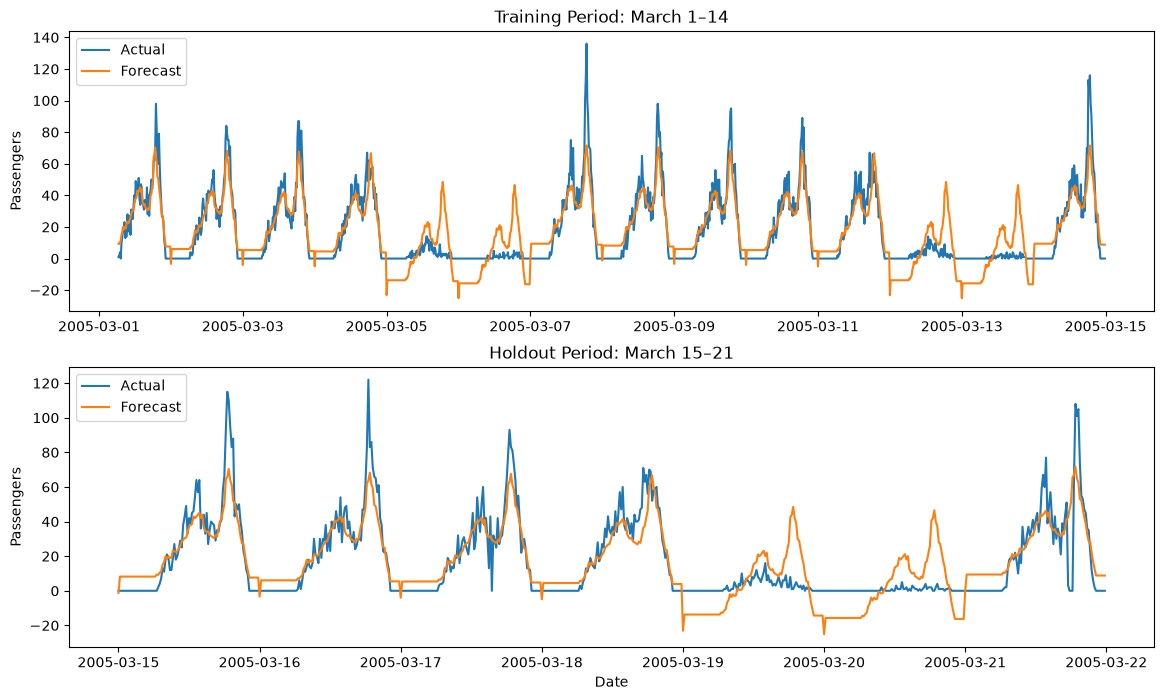

In [14]:
first_two_weeks_pred = forecaster_ARDL.predict(fh=ForecastingHorizon(first_two_weeks.index, is_relative=False),X=first_two_weeks_X)

third_week_pred = forecaster_ARDL.predict(fh=ForecastingHorizon(third_week.index, is_relative=False),X=third_week_X)

fig, axes = plt.subplots(2, 1, figsize=(14, 8)) #plot a 2 by 1 matrix plot of Training Period

axes[0].plot(first_two_weeks.index, first_two_weeks, label='Actual')
axes[0].plot(first_two_weeks_pred.index, first_two_weeks_pred, label='Forecast')
axes[0].set_title('Training Period: March 1–14')
axes[0].set_ylabel('Passengers')
axes[0].legend()
axes[1].plot(third_week.index, third_week, label='Actual')
axes[1].plot(third_week_pred.index, third_week_pred, label='Forecast')
axes[1].set_title('Holdout Period: March 15–21')
axes[1].set_ylabel('Passengers')
axes[1].set_xlabel('Date')
axes[1].legend()

plt.show()

The model seems to track well the week days (Monday-Friday) overall as the first plot shows the red and blue match up well. The model seems to struggle with training on weekends where there are little to no passengers and it struggles to find the peek hours of the week day. 

### Question 3 - Evaluate Model Performance

Report your model's accuracy on both the training and test periods using MAE, MAPE, and RMSE. Go
beyond the summary metrics: plot the actual and forecasted values overlaid on a time plot, and a
separate time plot of the forecast errors, and comment on where and when the model does well or poorly.
A model that forecasts reasonably well at any time of day and day of week is preferred over one that only
minimizes overall error.
Then address a practical wrinkle: several intervals have an actual demand of zero, and MAPE divides by
the actual value. Decide how you will handle these zero-demand intervals in the MAPE calculation and
justify your choice, noting that some of the zeros appear to be data errors rather than true zero demand.

In [15]:
print("Training: ")
zero_mask_tr = (first_two_weeks != 0) 
MAPE_first_two_weeks = ((first_two_weeks[zero_mask_tr] -first_two_weeks_pred[zero_mask_tr]).abs() / 
                        first_two_weeks[zero_mask_tr]).mean() *100
print(f' MAPE: {MAPE_first_two_weeks}')
mlba.regressionMetrics(y_true=first_two_weeks , y_pred=first_two_weeks_pred)

Training: 
 MAPE: 176.3490730561523


{'ME': np.float64(0.09279268513256697),
 'RMSE': 11.350095820456138,
 'MAE': np.float64(8.515146830462022)}

In [16]:
print("Holdout: ")
zero_mask_tst = (third_week != 0) 
MAPE_third_week = ((third_week[zero_mask_tst] -third_week_pred[zero_mask_tst]).abs() / 
                        third_week[zero_mask_tst]).mean() *100
print(f' MAPE: {MAPE_third_week}')
mlba.regressionMetrics(y_true=third_week,y_pred=third_week_pred)

Holdout: 
 MAPE: 190.1842183769301


{'ME': np.float64(0.027049729883111717),
 'RMSE': 12.552024877023628,
 'MAE': np.float64(9.213836505579904)}

The decision with the MAPE calcualations was to exclude all zeros from its calculations as if you did not it would 
result in undefined values. Even though there are some times throughout the day where zero passenger show up, MAPE metrics calculates based on how many passengers show up and therefore it isn't necessary to account for the 0 passengers during operating hours. 

In [17]:
def plot_model(forecaster, train_ts, holdout_ts, *, fh=None, train_X=None, holdout_X=None, ymax=175):
    if fh is None:
        fh=ForecastingHorizon(holdout_ts.index, is_relative=False)

    fig, axes = plt.subplots(nrows=2, figsize=(9,7.5))
    ax = plot_series(train_ts, holdout_ts,
        forecaster.predict(train_ts.index, X=train_X), forecaster.predict(fh, X=holdout_X),
        ax=axes[0], x_label='Time', y_label='Passengers',
        colors=['C0', 'C0', 'C3', 'C3'], markers=['','','',''])
    ax.axhline(y=0, color='grey')
    ax.axvline(train_ts.index[-1], color='grey')
    ax.set_ylim(-30, ymax)
    ax.text(train_ts.index[len(train_ts) // 2], ymax-20, "Training", 
            horizontalalignment='center')
    ax.text(holdout_ts.index[len(holdout_ts) // 2], ymax-20, "Holdout",
            horizontalalignment='center')

    train_res = forecaster.predict_residuals(train_ts, X=train_X)
    holdout_res = forecaster.predict_residuals(holdout_ts, X=holdout_X)
    ax = plot_series(train_res, holdout_res,
        ax=axes[1], x_label='Time', y_label='Residuals',
        colors=['C3', 'C3'], markers=['',''])
    ax.axhline(y=0, color='grey')
    ax.axvline(train_ts.index[-1], color='grey')
    ax.set_ylim(-70, 70)
    return axes



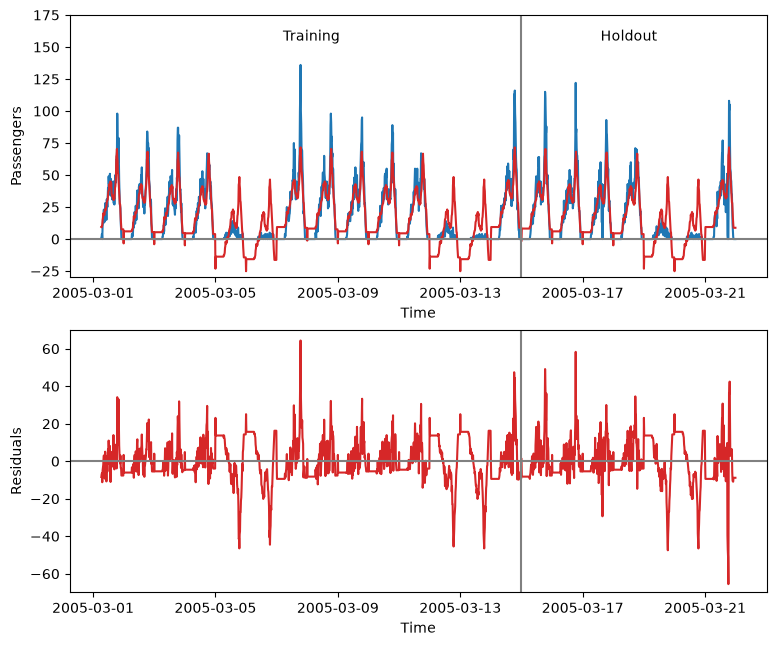

In [18]:
axes = plot_model(forecaster_ARDL, first_two_weeks, third_week, train_X=first_two_weeks_X, holdout_X=third_week_X)

### Question 4 - Forecast the Next Three Days and Summarize the Final Model
Refit your chosen model on the combined training-plus-test data (all three weeks of known demand), then
forecast demand for March 22 to 24 in 15-minute bins. Present a final model summary that includes:

- Method - the name of the method or combination of methods.
- Description - a brief description of how the method works.
- Equations - all estimated equations used to construct the forecasts.
- Accuracy - the MAPE and MAE for both the training and the test periods.
- Forecasts - the predicted demand for the future period (March 22 to 24), in 15-minute bins.
- Fit chart - a single chart showing the fit of the final model across the entire period (training, test, and the
three forecast days), with the model fitted on the combined training-plus-test data.

C:\Users\samsc\anaconda3\Lib\site-packages\sktime\forecasting\base\_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``True`` to ``False`` in sktime 1.3.0. After 1.3.0, ``BaseForecaster`` will no longer store incremental data in ``_X`` and ``_y`` by default. To silence this warning and adopt the new default early, set ``remember_data=False`` via ``set_config``. For forecasters that do not have update natively supported, i.e., the capability:update tag is not True, the default ``update`` will not refit. To keep storing incremental data and refitting on every update after the default change, set ``remember_data=True`` explicitly, or use ``UpdateRefitsEvery`` with ``refit_interval=0``.
  warn(


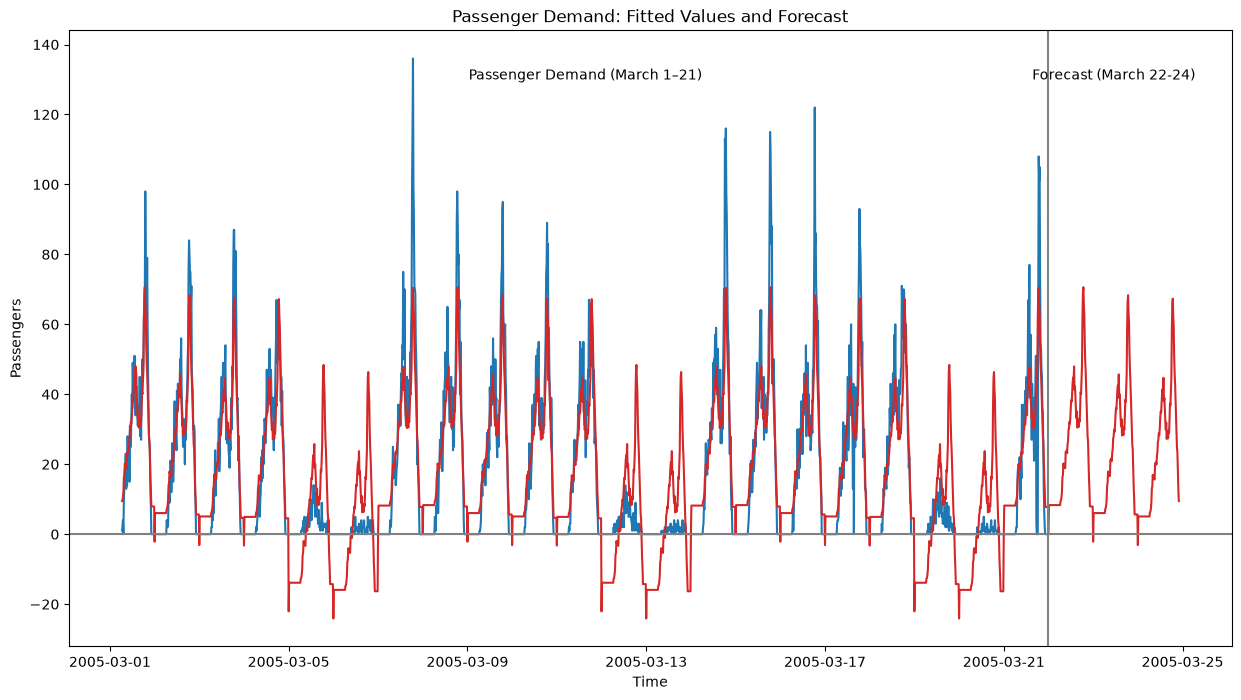

In [19]:
#Combine training and holdout 
three_weeks = pd.concat([first_two_weeks, third_week])

X = pd.DataFrame(index=ts.index) #create a dataframe with all timestamps

X['day_of_week'] = ts.index.dayofweek #retrieve day of week
X['time_of_day'] = ts.index.strftime('%H:%M') #retrieve time of day

#Convert categories into dummy variables
X = pd.get_dummies(X, columns=['day_of_week', 'time_of_day'], drop_first=True,dtype=int)

#Split predictors into training and holdout periods
three_weeks_X = X.loc[three_weeks.index]
future_forecast_X = X.loc[future_forecast.index]

future_ARDL = ARDL(lags=0, order=0, trend='n', seasonal=False)
future_ARDL.fit(three_weeks, X=three_weeks_X)
future_ARDL.summary()

three_weeks_pred = future_ARDL.predict(fh=ForecastingHorizon(three_weeks.index, is_relative=False),X=three_weeks_X)

future_forecast_pred = future_ARDL.predict(fh=ForecastingHorizon(future_forecast.index, is_relative=False),X=future_forecast_X)

fig, ax = plt.subplots(figsize=(15, 8))
plot_series(three_weeks, future_forecast,
    three_weeks_pred, future_forecast_pred,
    ax=ax, x_label='Time', y_label='Passengers',
    colors=['C0', 'C0', 'C3', 'C3'], markers=['','','',''])

ax.axhline(y=0, color='grey')
ax.axvline(three_weeks.index[-1], color='grey')
ymax = 200
ax.text(three_weeks.index[len(three_weeks) // 2], ymax-70, "Passenger Demand (March 1–21)", 
        horizontalalignment='center')
ax.text(future_forecast.index[len(future_forecast) // 2], ymax-70, "Forecast (March 22-24)",
        horizontalalignment='center')
ax.set_title('Passenger Demand: Fitted Values and Forecast')
plt.show()

The method of the model I used is ARDL regression model with daily and weekly seasonal dummy predictors and time of day dummy variables. ime-of-day dummy variables were used to capture recurring patterns in passenger demand throughout the day, while day-of-week dummy variables captured differences in demand across the days of the week. The model was initially trained on the first two weeks of data and evaluated on the third week. After evaluating its performance, the model was refitted using all three weeks of known passenger demand to forecast the next three days, March 22–24.
The regression equation used to represent the model is:

$$ \hat{y}_t = \beta_0 + \sum_{h=1}^{H-1} \gamma_h T_{h,t} + \sum_{d=1}^{6} \delta_d D_{d,t} + \varepsilon_t $$

Accuracy scores were measured and tracked using both Mean Absolute Percentage Error (MAPE) and Mean Absolute Error (MAE). The training data measured the first two weeks of the data and it's MAPE scored measured 176.1842 and the MAE scored 8.5151. Holdout score measured the last week before the three day forecast, and the holdout MAPE measured to be 190.1842 and the MAE measured to be 9.2138. The holdout score is higher because the ARDL model had a more difficult time learning the unseen data.

In [22]:
results = pd.DataFrame({
    'Date and Time': future_forecast_pred.index,
    'Forecast Demand': future_forecast_pred.values
})

results

,Date and Time,Forecast Demand
0,2005-03-22 00:00:00,0.141872
1,2005-03-22 00:15:00,8.323436
2,2005-03-22 00:30:00,8.323436
3,2005-03-22 00:45:00,8.323436
4,2005-03-22 01:00:00,8.323436
...,...,...
276,2005-03-24 21:00:00,24.720438
277,2005-03-24 21:15:00,23.291867
278,2005-03-24 21:30:00,17.577581
279,2005-03-24 21:45:00,12.720438
